# Oracle score distributions

Compare QA-generated sequences from bVAE and pLM-bVAE (HPO) for AAV capsid surface region variants. The oracle score is the mean prediction of the three predictors; the reference threshold is derived from training and validation sequences.

In [1]:
# Compare oracle score distributions of QA-generated sequences and training and validation data for AAV capsid variants.
# Import libraries for data handling and visualization.
import pandas as pd
import json
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import warnings
warnings.filterwarnings("ignore")

import matplotlib as mpl
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['axes.unicode_minus'] = False

## Load generated sequences and predictor scores

In [2]:
# Load sequences generated by bVAE and their predicted scores across runs; calculate the mean predictor score.
# Load the data.
plm_res = "c:\\Users\\hueda8\\Desktop\\MyPaper\\pLM-bVAE_paper\\github_repository\\pLM-bVAE\\reproduction_paper\\outputs\\"
# bvae
bvae_all_sample1 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa1\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
bvae_all_sample2 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa2\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
bvae_all_sample3 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa3\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
bvae_all_sample4 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa4\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
bvae_all_sample5 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa5\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
bvae_all_sample6 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa6\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
bvae_all_sample7 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa7\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
bvae_all_sample8 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa8\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
bvae_all_sample9 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa9\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
bvae_all_sample10 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa10\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])

# Load the sequences.
# bvae decoded_list
bvae_decoded1 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa1\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
bvae_decoded2 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa2\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
bvae_decoded3 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa3\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
bvae_decoded4 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa4\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
bvae_decoded5 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa5\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
bvae_decoded6 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa6\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
bvae_decoded7 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa7\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
bvae_decoded8 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa8\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
bvae_decoded9 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa9\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
bvae_decoded10 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa10\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])

# Merge decoded sequences with sampled data.
bvae_all_sample1 = pd.concat([bvae_decoded1, bvae_all_sample1], axis=1)
bvae_all_sample2 = pd.concat([bvae_decoded2, bvae_all_sample2], axis=1)
bvae_all_sample3 = pd.concat([bvae_decoded3, bvae_all_sample3], axis=1)
bvae_all_sample4 = pd.concat([bvae_decoded4, bvae_all_sample4], axis=1)
bvae_all_sample5 = pd.concat([bvae_decoded5, bvae_all_sample5], axis=1)
bvae_all_sample6 = pd.concat([bvae_decoded6, bvae_all_sample6], axis=1)
bvae_all_sample7 = pd.concat([bvae_decoded7, bvae_all_sample7], axis=1)
bvae_all_sample8 = pd.concat([bvae_decoded8, bvae_all_sample8], axis=1)
bvae_all_sample9 = pd.concat([bvae_decoded9, bvae_all_sample9], axis=1)
bvae_all_sample10 = pd.concat([bvae_decoded10, bvae_all_sample10], axis=1)

# Combine the ten bVAE runs.
bvae_all_samples = pd.concat([bvae_all_sample1, bvae_all_sample2, bvae_all_sample3, bvae_all_sample4, bvae_all_sample5, bvae_all_sample6, bvae_all_sample7, bvae_all_sample8, bvae_all_sample9, bvae_all_sample10], ignore_index=True)
len(bvae_all_samples)

# Remove whitespace from each amino acid sequence.
bvae_all_samples['seq'] = bvae_all_samples['seq'].str.replace(' ', '')

# Average the three predictor scores in bb_score_avg.
bvae_all_samples['bb_score_avg'] = bvae_all_samples[['bb_score1', 'bb_score2', 'bb_score3']].mean(axis=1)

len(bvae_all_samples)

20000

In [3]:
# Load sequences generated by pLM-bVAE (HPO) and their predicted scores across runs; calculate the mean predictor score.
# esm_650m_opt
esm_650m_opt_all_sample1 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa1\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
esm_650m_opt_all_sample2 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa2\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
esm_650m_opt_all_sample3 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa3\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
esm_650m_opt_all_sample4 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa4\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
esm_650m_opt_all_sample5 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa5\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
esm_650m_opt_all_sample6 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa6\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads","fm_score"])
esm_650m_opt_all_sample7 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa7\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
esm_650m_opt_all_sample8 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa8\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
esm_650m_opt_all_sample9 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa9\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
esm_650m_opt_all_sample10 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa10\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
# esm_650m_opt decoded_list
esm_650m_opt_decoded1 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa1\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
esm_650m_opt_decoded2 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa2\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
esm_650m_opt_decoded3 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa3\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
esm_650m_opt_decoded4 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa4\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
esm_650m_opt_decoded5 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa5\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
esm_650m_opt_decoded6 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa6\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
esm_650m_opt_decoded7 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa7\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
esm_650m_opt_decoded8 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa8\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
esm_650m_opt_decoded9 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa9\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
esm_650m_opt_decoded10 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa10\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])

# Merge decoded sequences with sampled data.
esm_650m_opt_all_sample1 = pd.concat([esm_650m_opt_decoded1, esm_650m_opt_all_sample1], axis=1)
esm_650m_opt_all_sample2 = pd.concat([esm_650m_opt_decoded2, esm_650m_opt_all_sample2], axis=1)
esm_650m_opt_all_sample3 = pd.concat([esm_650m_opt_decoded3, esm_650m_opt_all_sample3], axis=1)
esm_650m_opt_all_sample4 = pd.concat([esm_650m_opt_decoded4, esm_650m_opt_all_sample4], axis=1)
esm_650m_opt_all_sample5 = pd.concat([esm_650m_opt_decoded5, esm_650m_opt_all_sample5], axis=1)
esm_650m_opt_all_sample6 = pd.concat([esm_650m_opt_decoded6, esm_650m_opt_all_sample6], axis=1)
esm_650m_opt_all_sample7 = pd.concat([esm_650m_opt_decoded7, esm_650m_opt_all_sample7], axis=1)
esm_650m_opt_all_sample8 = pd.concat([esm_650m_opt_decoded8, esm_650m_opt_all_sample8], axis=1)
esm_650m_opt_all_sample9 = pd.concat([esm_650m_opt_decoded9, esm_650m_opt_all_sample9], axis=1)
esm_650m_opt_all_sample10 = pd.concat([esm_650m_opt_decoded10, esm_650m_opt_all_sample10], axis=1)


# Combine the ten pLM-bVAE (HPO) runs.
esm_650m_opt_all_samples = pd.concat([esm_650m_opt_all_sample1, esm_650m_opt_all_sample2, esm_650m_opt_all_sample3, esm_650m_opt_all_sample4, esm_650m_opt_all_sample5, esm_650m_opt_all_sample6, esm_650m_opt_all_sample7, esm_650m_opt_all_sample8, esm_650m_opt_all_sample9, esm_650m_opt_all_sample10], ignore_index=True)
len(esm_650m_opt_all_samples)

# Remove whitespace from each amino acid sequence.
esm_650m_opt_all_samples['seq'] = esm_650m_opt_all_samples['seq'].str.replace(' ', '')

# Average the three predictor scores in bb_score_avg.
esm_650m_opt_all_samples['bb_score_avg'] = esm_650m_opt_all_samples[['bb_score1', 'bb_score2', 'bb_score3']].mean(axis=1)
len(esm_650m_opt_all_samples)

19970

## Load training and validation sequences

In [4]:
# Load the training and validation sequences used as the reference set.
# Load the training data.
plm_data = "c:\\Users\\hueda8\\Desktop\\MyPaper\\pLM-bVAE_paper\\github_repository\\pLM-bVAE\\reproduction_paper\\data\\"
train_seqs = pd.read_csv(plm_data + "aav\\bvae\\train.txt", sep="\t", header=None, names=["seq"])
train_seqs["seq"] = train_seqs["seq"].str.replace(" ", "")

# Load the validation data.
dev_seqs = pd.read_csv(plm_data + "aav\\bvae\\dev.txt", sep="\t", header=None, names=["seq"])
dev_seqs["seq"] = dev_seqs["seq"].str.replace(" ", "")

# Combine the training and validation data.
train_dev_seqs = pd.concat([train_seqs, dev_seqs], ignore_index=True)

## Filter penalized and duplicate sequences

In [5]:
# Identify and exclude sequences assigned the penalty score.
# Count rows with a penalty score of -1e6.
print((bvae_all_samples['bb_score1'] == -1e6).sum())
print((esm_650m_opt_all_samples['bb_score1'] == -1e6).sum())

# Exclude rows with a penalty score of -1e6.
bvae_all_samples_del_penalty = bvae_all_samples[bvae_all_samples['bb_score1'] != -1e6]
esm_650m_opt_all_samples_del_penalty = esm_650m_opt_all_samples[esm_650m_opt_all_samples['bb_score1'] != -1e6]

99
0


In [6]:
# Inspect and remove duplicate generated sequences.
# Count duplicate sequences.
print(bvae_all_samples_del_penalty.duplicated(subset=['seq']).sum())
print(esm_650m_opt_all_samples_del_penalty.duplicated(subset=['seq']).sum())

# Remove duplicate sequences.
bvae_all_samples_del_penalty_unique = bvae_all_samples_del_penalty.drop_duplicates(subset=['seq'])
esm_650m_opt_all_samples_del_penalty_unique = esm_650m_opt_all_samples_del_penalty.drop_duplicates(subset=['seq'])

14428
556


In [7]:
# Exclude generated sequences present in the training and validation data and remove duplicates.
# Check whether generated bVAE sequences overlap with training and validation sequences.
bvae_in_train_dev = bvae_all_samples_del_penalty['seq'].isin(train_dev_seqs['seq'])
esm_650m_opt_in_train_dev = esm_650m_opt_all_samples_del_penalty_unique['seq'].isin(train_dev_seqs['seq'])
print(f"bVAE generated rows matching training or validation sequences: {bvae_in_train_dev.sum()}")
print(f"Unique pLM-bVAE (HPO) sequences matching training or validation sequences: {esm_650m_opt_in_train_dev.sum()}")

# Remove duplicate sequences.
bvae_all_samples_del_penalty_unique_train_dev = bvae_all_samples_del_penalty_unique[~bvae_in_train_dev]
esm_650m_opt_all_samples_del_penalty_unique_train_dev = esm_650m_opt_all_samples_del_penalty_unique[~esm_650m_opt_in_train_dev]

bVAE generated rows matching training or validation sequences: 245
Unique pLM-bVAE (HPO) sequences matching training or validation sequences: 1


In [8]:
# Inspect the number of retained sequences.
# Check the number of sequences.
print(f"Unique bVAE sequences excluding training and validation sequences: {len(bvae_all_samples_del_penalty_unique_train_dev)}")
print(f"Unique pLM-bVAE (HPO) sequences excluding training and validation sequences: {len(esm_650m_opt_all_samples_del_penalty_unique_train_dev)}")

Unique bVAE sequences excluding training and validation sequences: 5464
Unique pLM-bVAE (HPO) sequences excluding training and validation sequences: 19413


## Calculate the reference oracle score

In [9]:
# Load predictor scores for the training and validation data and calculate their mean.
# Load the training and validation data.
pred_train_val1 = pd.read_csv(plm_res +'parrot\\pred_parrot_train_val_sets\\pred_parrot1_aav_train_val_sets.txt', sep=" ", header=None, names=["id", "seq", "bb_score"])
pred_train_val2 = pd.read_csv(plm_res +'parrot\\pred_parrot_train_val_sets\\pred_parrot2_aav_train_val_sets.txt', sep=" ", header=None, names=["id", "seq", "bb_score"])
pred_train_val3 = pd.read_csv(plm_res +'parrot\\pred_parrot_train_val_sets\\pred_parrot3_aav_train_val_sets.txt', sep=" ", header=None, names=["id", "seq", "bb_score"])
# Calculate the mean predictor score for the training and validation data.
pred_train_val1['bb_score_avg'] = (pred_train_val1['bb_score'] + pred_train_val2['bb_score'] + pred_train_val3['bb_score']) / 3

In [10]:
# Find the reference score corresponding to the tenth-ranked training and validation sequence.
# Find the tenth-ranked training and validation score.
pred_train_val_bb_score_top10 = pred_train_val1.sort_values(by='bb_score_avg', ascending=False).iloc[9]['bb_score_avg']
print(pred_train_val_bb_score_top10)
# Convert the log2 score back to its original scale.
print(2 ** pred_train_val_bb_score_top10)

1.2833956666666666
2.4341121937448453


In [11]:
# Count generated sequences meeting the reference score threshold.
# Count generated sequences at or above the reference score.
bvae_top10_count = (bvae_all_samples_del_penalty_unique_train_dev['bb_score_avg'] >= pred_train_val_bb_score_top10).sum()
esm_top10_count = (esm_650m_opt_all_samples_del_penalty_unique_train_dev['bb_score_avg'] >= pred_train_val_bb_score_top10).sum()
print(f"bVAE sequences with oracle scores at or above the reference threshold: {bvae_top10_count}")
print(f"pLM-bVAE (HPO) sequences with oracle scores at or above the reference threshold: {esm_top10_count}")

bVAE sequences with oracle scores at or above the reference threshold: 19
pLM-bVAE (HPO) sequences with oracle scores at or above the reference threshold: 2761


In [12]:
bvae_all_samples_del_penalty_unique_train_dev['bb_score_avg'].sort_values(ascending=False).head(50)

8099     1.362454
12701    1.336477
7128     1.329518
7367     1.317599
7752     1.315390
9098     1.314217
2840     1.310866
1482     1.303386
6207     1.299600
10724    1.299443
18098    1.296839
1143     1.295935
14282    1.294609
13801    1.294110
11544    1.293902
2230     1.289762
1287     1.287077
770      1.284088
3528     1.283963
1032     1.273230
12686    1.271157
13773    1.269151
15410    1.268968
1528     1.265686
16820    1.265681
7527     1.263119
1118     1.260349
3146     1.260225
12510    1.258489
8104     1.257366
5993     1.256449
18246    1.255993
1265     1.255893
15832    1.255315
7711     1.254510
18820    1.253228
4535     1.251798
19874    1.251617
18927    1.250739
1100     1.250548
7491     1.249875
2057     1.249034
7181     1.248384
11883    1.246078
312      1.245662
950      1.245290
13740    1.243664
8690     1.243261
4260     1.242881
5111     1.242002
Name: bb_score_avg, dtype: float64

## Normalize and plot oracle scores

In [13]:
# Combine the score data for the models and the reference set.
# Combine the generated and reference scores for comparison.
combined_df = pd.DataFrame({
    'bb_score_avg': np.concatenate([
        bvae_all_samples_del_penalty_unique_train_dev['bb_score_avg'].values,
        esm_650m_opt_all_samples_del_penalty_unique_train_dev['bb_score_avg'].values,
        pred_train_val1['bb_score_avg'].values
    ]),
    'model': ['bVAE'] * len(bvae_all_samples_del_penalty_unique_train_dev) + ['ESM2_650M-bVAE (HPO)'] * len(esm_650m_opt_all_samples_del_penalty_unique_train_dev) + ['train/val'] * len(pred_train_val1)
})

In [14]:
# Transform and min-max scale the scores for comparison.
# Apply min-max normalization without reversing the score sign.
combined_df['bb_score_avg_transformed'] = combined_df['bb_score_avg'] # Retain the original score sign.
combined_df['bb_score_avg_normalized'] = (combined_df['bb_score_avg_transformed'] - combined_df['bb_score_avg_transformed'].min()) / (combined_df['bb_score_avg_transformed'].max() - combined_df['bb_score_avg_transformed'].min())

# Inspect the rows with the minimum and maximum normalized scores.
print(combined_df.loc[combined_df['bb_score_avg_normalized'].idxmin()])
print(combined_df.loc[combined_df['bb_score_avg_normalized'].idxmax()])

bb_score_avg                -7.574328
model                       train/val
bb_score_avg_transformed    -7.574328
bb_score_avg_normalized           0.0
Name: 33138, dtype: object
bb_score_avg                            1.462511
model                       ESM2_650M-bVAE (HPO)
bb_score_avg_transformed                1.462511
bb_score_avg_normalized                      1.0
Name: 17141, dtype: object


In [15]:
# Identify the tenth-ranked training and validation score on the scaled axis.
# Find the tenth-ranked normalized training and validation score.
top10_train_val = combined_df[(combined_df['model'] == 'train/val')].sort_values(by='bb_score_avg_normalized', ascending=False).iloc[9]['bb_score_avg_normalized']
top10_train_val

np.float64(0.9801794789794589)

In [16]:
# Count generated sequences meeting the scaled reference score threshold.
# Count generated sequences at or above the normalized reference score.
bvae_top10_count = (combined_df[(combined_df['model'] == 'bVAE')]['bb_score_avg_normalized'] >= top10_train_val).sum()
esm_top10_count = (combined_df[(combined_df['model'] == 'ESM2_650M-bVAE (HPO)')]['bb_score_avg_normalized'] >= top10_train_val).sum()
print(f"bVAE sequences with normalized oracle scores at or above the reference threshold: {bvae_top10_count}")
print(f"ESM2_650M-bVAE (HPO) sequences with normalized oracle scores at or above the reference threshold: {esm_top10_count}")

bVAE sequences with normalized oracle scores at or above the reference threshold: 19
ESM2_650M-bVAE (HPO) sequences with normalized oracle scores at or above the reference threshold: 2761


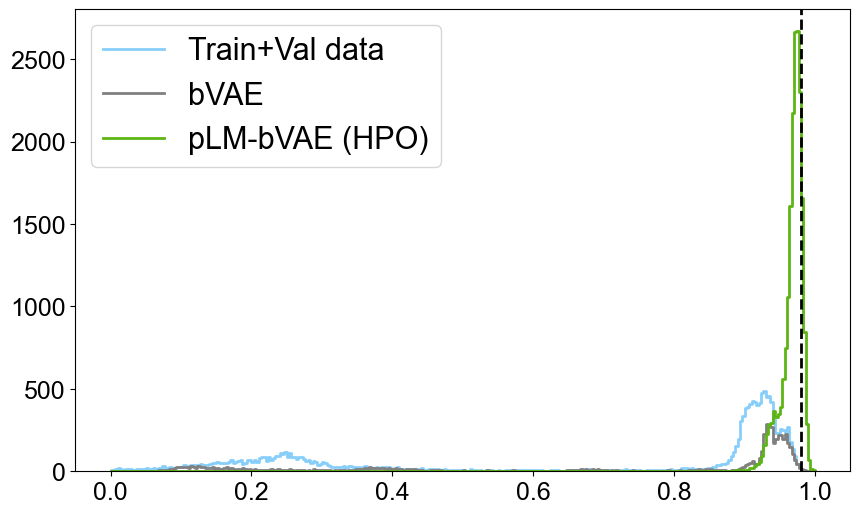

In [17]:
# Plot the oracle score distributions.
plt.figure(figsize=(10, 6))

# Define common bins.
bins = np.linspace(0, 1, 301)

def plot_step_hist_with_zero(data, bins, color, label, linewidth=2):
    counts, edges = np.histogram(data, bins=bins)

    # Create coordinates for the step plot.
    x = edges
    y = np.r_[counts, counts[-1]]

    # Extend both ends of the step plot to zero.
    x_plot = np.r_[edges[0], x, edges[-1]]
    y_plot = np.r_[0, y, 0]

    plt.step(
        x_plot,
        y_plot,
        where="post",
        color=color,
        linewidth=linewidth,
        label=label,
    )

plot_step_hist_with_zero(
    combined_df[combined_df["model"] == "train/val"]["bb_score_avg_normalized"],
    bins=bins,
    color="lightskyblue",
    label="Train+Val data",
)

plot_step_hist_with_zero(
    combined_df[combined_df["model"] == "bVAE"]["bb_score_avg_normalized"],
    bins=bins,
    color="gray",
    label="bVAE",
)

plot_step_hist_with_zero(
    combined_df[combined_df["model"] == "ESM2_650M-bVAE (HPO)"]["bb_score_avg_normalized"],
    bins=bins,
    color="#5CB514",
    label="pLM-bVAE (HPO)",
)

plt.axvline(x=top10_train_val, color="black", linestyle="--", linewidth=2)

plt.xlabel("")
plt.ylabel("")
plt.ylim(0, )

plt.xticks(
    fontsize=18,
    ticks=[0.0, 0.2, 0.4, 0.6, 0.8, 1.0],
)
plt.yticks(fontsize=18)

plt.legend(fontsize=22)
plt.show()

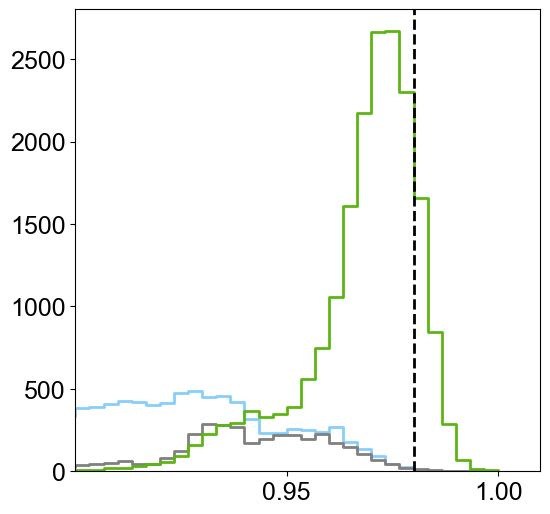

In [18]:
# Plot the score distributions near the reference threshold.
plt.figure(figsize=(6, 6))

# Define common bins.
bins = np.linspace(0, 1, 301)

def plot_step_hist_with_zero(data, bins, color, label, linewidth=2):
    counts, edges = np.histogram(data, bins=bins)

    # Create coordinates for the step plot.
    x = edges
    y = np.r_[counts, counts[-1]]

    # Extend both ends of the step plot to zero.
    x_plot = np.r_[edges[0], x, edges[-1]]
    y_plot = np.r_[0, y, 0]

    plt.step(
        x_plot,
        y_plot,
        where="post",
        color=color,
        linewidth=linewidth,
        label=label,
    )

plot_step_hist_with_zero(
    combined_df[combined_df["model"] == "train/val"]["bb_score_avg_normalized"],
    bins=bins,
    color="lightskyblue",
    label="Train/Val data",
)

plot_step_hist_with_zero(
    combined_df[combined_df["model"] == "bVAE"]["bb_score_avg_normalized"],
    bins=bins,
    color="gray",
    label="bVAE",
)

plot_step_hist_with_zero(
    combined_df[combined_df["model"] == "ESM2_650M-bVAE (HPO)"]["bb_score_avg_normalized"],
    bins=bins,
    color="#5CB514",
    label="pLM-bVAE (HPO)",
)

plt.axvline(x=top10_train_val, color="black", linestyle="--", linewidth=2)

plt.xlabel("")
plt.ylabel("")
plt.xlim(0.9, 1.01)
plt.ylim(0, )

plt.xticks(
    fontsize=18,
    ticks=[0.950, 1.000],
)
plt.yticks(fontsize=18)

# plt.legend(fontsize=22)
plt.show()